In [36]:
import json
lines = []
with open('nuevo.jl') as f:
    for line in f:
        lines.append(json.loads(line))

In [37]:
len(lines)

28273

In [61]:
from collections import defaultdict

x = []
y = []
d = defaultdict(list)
for e in lines:
    # if e['t1'] != 0 : continue
    player = len(e['ms']) % 2
    temp = e['t1'] if player == 0 else e['t2']
    x.append(temp)
    y.append(e['severity'])
    t1,t2 = (e['t1'], e['t2']) if player == 0 else (e['t2'], e['t1'])
    d[e['severity']].append(round(t1-t2))#temp)



In [62]:
sorted(Counter(d[1]).items())

[(-18, 101),
 (-16, 274),
 (-13, 450),
 (-11, 641),
 (-9, 782),
 (-7, 1016),
 (-4, 1205),
 (-2, 1515),
 (0, 1695),
 (2, 1569),
 (4, 1368),
 (7, 1160),
 (9, 973),
 (11, 798),
 (13, 568),
 (16, 417),
 (18, 194),
 (20, 65)]

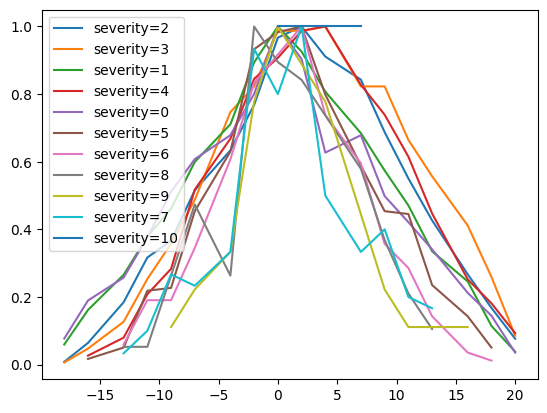

In [64]:
l = [{'severity': k, 'temp_distr': dict(Counter(v))} for k, v in d.items()]
for doc in l:
    x, y= zip(*sorted(doc['temp_distr'].items()))
    y = [e/max(y) for e in y]
    plt.plot(x, y, label='severity={}'.format(doc['severity']))
plt.legend(loc='best')


In [44]:
[{'temperature': k, 'severity_distr': dict(Counter(v))} for k, v in d.items()]

[{'temperature': 2.222, 'severity_distr': {2: 9, 3: 2, 1: 4}},
 {'temperature': 4.444, 'severity_distr': {4: 8, 2: 22, 1: 5, 3: 9}},
 {'temperature': 6.667, 'severity_distr': {3: 12, 2: 22, 1: 6, 4: 5}},
 {'temperature': 8.889, 'severity_distr': {4: 8, 2: 20, 3: 16, 1: 5}},
 {'temperature': 11.111, 'severity_distr': {3: 17, 2: 16, 4: 16, 1: 1}},
 {'temperature': 13.333, 'severity_distr': {2: 18, 3: 19, 4: 14, 1: 2}},
 {'temperature': 15.556, 'severity_distr': {4: 12, 2: 19, 1: 4, 3: 14}},
 {'temperature': 17.778, 'severity_distr': {2: 18, 3: 15, 4: 15, 1: 5}},
 {'temperature': 20, 'severity_distr': {2: 20, 4: 12, 3: 12, 1: 4}}]

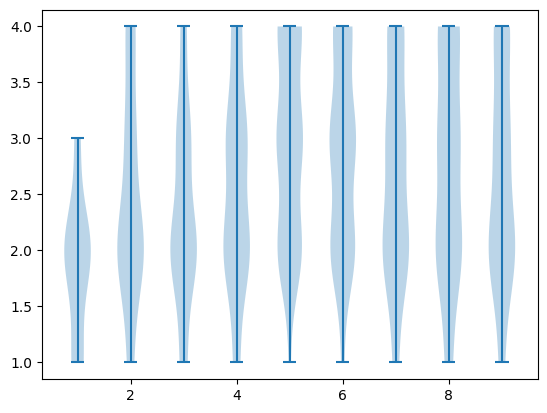

In [41]:
plt.violinplot(list(d.values()));

In [18]:
from collections import defaultdict

d = defaultdict(list)

for xi, yi in zip(x,y):
    

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [14]:
import matplotlib.pyplot as plt

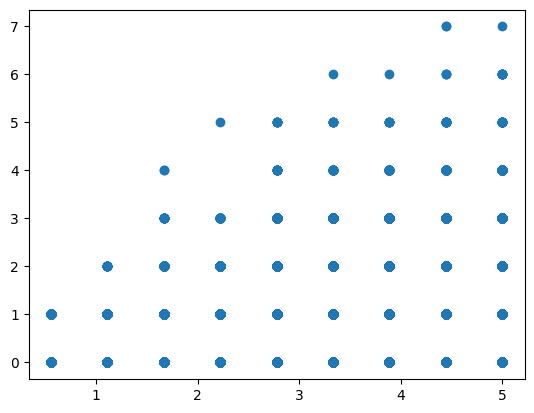

In [15]:
plt.scatter(x,y)

In [67]:
from collections import Counter

cnt = Counter()
for e in lines:
    cnt[e['severity']]+=1

In [70]:
s = sum(cnt.values())
    
[{'severity': k, 'frequency': f'{v/s*100:.02f}%'} for k, v in  sorted(cnt.items())]

[{'severity': 0, 'frequency': '9.20%'},
 {'severity': 1, 'frequency': '52.31%'},
 {'severity': 2, 'frequency': '14.95%'},
 {'severity': 3, 'frequency': '10.56%'},
 {'severity': 4, 'frequency': '6.94%'},
 {'severity': 5, 'frequency': '3.04%'},
 {'severity': 6, 'frequency': '1.87%'},
 {'severity': 7, 'frequency': '0.56%'},
 {'severity': 8, 'frequency': '0.39%'},
 {'severity': 9, 'frequency': '0.16%'},
 {'severity': 10, 'frequency': '0.01%'}]

In [90]:
filtered = [e for e in lines if e['severity'] == 3]

In [91]:
import os
for e in filtered[:10]:
    print('move', e['move'])
    print('sev', e['severity'])
    os.system('./visualize_board.sh {} | head -n 10'.format(e['ms'])) 

move 2
sev 3
  Move 13  |  Next: Yellow

       1   2   3   4   5   6   7 
  6  |   |   |   |   |   |   |   |
  5  |   |   |   | Y |   |   |   |
  4  |   |   |   | R |   |   |   |
  3  |   | R |   | R | Y |   |   |
  2  |   | R |   | Y | R |   |   |
  1  | Y | R |   | R | Y |   | Y |

move 2
sev 3
  Move 13  |  Next: Yellow

       1   2   3   4   5   6   7 
  6  |   |   |   |   |   |   |   |
  5  |   |   |   | Y |   |   |   |
  4  |   |   |   | R |   |   |   |
  3  |   |   |   | R | Y |   |   |
  2  |   | R |   | Y | R |   |   |
  1  | Y | Y | R | R | R |   | Y |

move 4
sev 3
  Move 9  |  Next: Yellow

       1   2   3   4   5   6   7 
  6  |   |   |   |   |   |   |   |
  5  |   |   |   |   |   |   |   |
  4  |   |   |   |   |   |   |   |
  3  |   |   |   | R |   |   |   |
  2  |   |   | Y | R |   |   |   |
  1  |   | Y | Y | R | R | R | Y |

move 1
sev 3
  Move 13  |  Next: Yellow

       1   2   3   4   5   6   7 
  6  |   |   |   |   |   |   |   |
  5  |   |   |   |   |   |   |   